In [1]:
# add auto reload
%load_ext autoreload
%autoreload 2

In [2]:
import os
from pathlib import Path
import torch
from transformers import AutoModelForCausalLM, AutoTokenizer
# Import our custom functions
from llm_chapter import (
    ask_smol_lm, 
    get_next_word_suggestions, 
    generate_text_step_by_step
)

In [3]:
local_cache_dir = "./models_cache"  # or an absolute path
# Create directory if it doesn't exist
Path(local_cache_dir).mkdir(parents=True, exist_ok=True)
# Load model with custom cache directory
model_id = "HuggingFaceTB/SmolLM2-1.7B-Instruct"
# This will download once and store in your specified directory
tokenizer = AutoTokenizer.from_pretrained(model_id, cache_dir=local_cache_dir)
model = AutoModelForCausalLM.from_pretrained(model_id,cache_dir=local_cache_dir,device_map="auto",torch_dtype=torch.float16,low_cpu_mem_usage=True)

print("✅ Model loaded from cache directory!")
print(f"Files stored in: {local_cache_dir}")
device = model.device
print("Using device:", device)

✅ Model loaded from cache directory!
Files stored in: ./models_cache
Using device: mps:0


In [4]:
print(ask_smol_lm("Explain Bayesian inference in one simple sentence.", model, tokenizer))
print(ask_smol_lm("What is the capital of France?.", model, tokenizer))

Bayesian inference is a statistical method that uses probability to update the likelihood of a hypothesis as more data becomes available, using Bayes' theorem to balance prior knowledge with new evidence.
The capital of France is Paris.


In [5]:
# Example: Get suggestions for next word
text = "The best thing about AI is its ability to"
print(f"Text: '{text}'")
print("=" * 50)
suggestions = get_next_word_suggestions(text, model, tokenizer, top_k=20)
print(suggestions[0:5])  # Show top 4 suggestions

Text: 'The best thing about AI is its ability to'
[(' learn', 0.3759765625), (' help', 0.07177734375), (' augment', 0.0604248046875), (' analyze', 0.0509033203125), (' process', 0.044921875)]


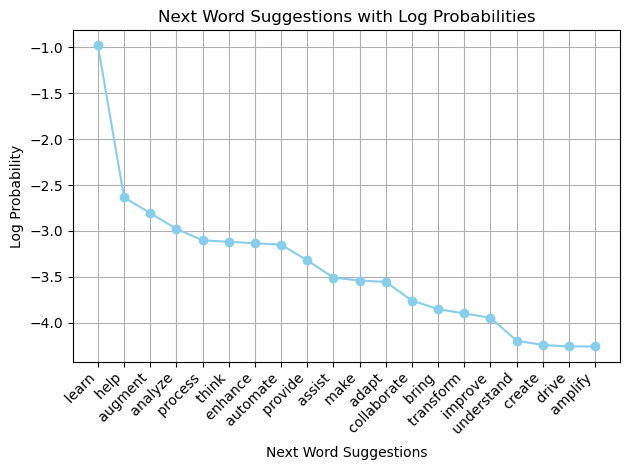

In [9]:
import matplotlib.pyplot as plt
import numpy as np
indices = list(range(len(suggestions)))
words = [s[0] for s in suggestions]
probabilities = [s[1] for s in suggestions]
# Plotting the next word suggestions with their log probabilities
plt.plot(indices, np.log(probabilities), marker='o', linestyle='-', color='skyblue')
plt.xticks(indices, words, rotation=45, ha='right')
plt.xlabel('Next Word Suggestions')
plt.ylabel('Log Probability')
plt.title('Next Word Suggestions with Log Probabilities')
plt.grid()
plt.tight_layout()
plt.show()

In [10]:
# Example: Generate text step by step
initial_text = "The best thing about AI is its ability to"
generated_text = generate_text_step_by_step(initial_text, model, tokenizer, num_steps=6)

Starting text: 'The best thing about AI is its ability to'
'The best thing about AI is its ability to learn' (prob: 0.280)
'The best thing about AI is its ability to learn and' (prob: 0.697)
'The best thing about AI is its ability to learn and adapt' (prob: 0.481)
'The best thing about AI is its ability to learn and adapt.' (prob: 0.321)
'The best thing about AI is its ability to learn and adapt. It' (prob: 0.260)
'The best thing about AI is its ability to learn and adapt. It can' (prob: 0.529)


In [11]:
generated_text = generate_text_step_by_step(initial_text, model, tokenizer, num_steps=6, temperature=2, sample=True)

Starting text: 'The best thing about AI is its ability to'
'The best thing about AI is its ability to increase' (prob: 0.001)
'The best thing about AI is its ability to increase efficiency' (prob: 0.429)
'The best thing about AI is its ability to increase efficiency human' (prob: 0.000)
'The best thing about AI is its ability to increase efficiency human like' (prob: 0.002)
'The best thing about AI is its ability to increase efficiency human like smart' (prob: 0.005)
'The best thing about AI is its ability to increase efficiency human like smart capabilities' (prob: 0.001)


In [12]:
generated_text = generate_text_step_by_step(initial_text, model, tokenizer, num_steps=6, temperature=2, sample=True)

Starting text: 'The best thing about AI is its ability to'
'The best thing about AI is its ability to aid' (prob: 0.004)
'The best thing about AI is its ability to aid doctors' (prob: 0.003)
'The best thing about AI is its ability to aid doctors remove' (prob: 0.000)
'The best thing about AI is its ability to aid doctors remove malignant' (prob: 0.007)
'The best thing about AI is its ability to aid doctors remove malignant tumors' (prob: 0.492)
'The best thing about AI is its ability to aid doctors remove malignant tumors without' (prob: 0.021)


In [22]:
torch.manual_seed(8);
generated_text = generate_text_step_by_step(initial_text, model, tokenizer, num_steps=60, temperature=0.8, sample=True,print_progress=False)
print("Generated text:")
print(generated_text)

Generated text:
The best thing about AI is its ability to learn and improve over time. By continuously gathering data and analyzing its performance, AI systems can refine their decision-making processes to become more effective and efficient. This means that as AI systems encounter new data, they can adapt and learn from their experiences, leading to better outcomes."



4


In [23]:
generated_text = generate_text_step_by_step(initial_text, model, tokenizer, num_steps=60, temperature=1.2, sample=True,print_progress=False)
print("Generated text:")
print(generated_text)

Generated text:
The best thing about AI is its ability to assist and augment human capabilities. It could enable people to live their lives more efficiently, focus on high-value activities, and provide critical support when humans are not available or capable, such as monitoring critical infrastructure, responding to emergencies, or providing healthcare support in areas with limited resources.

2)


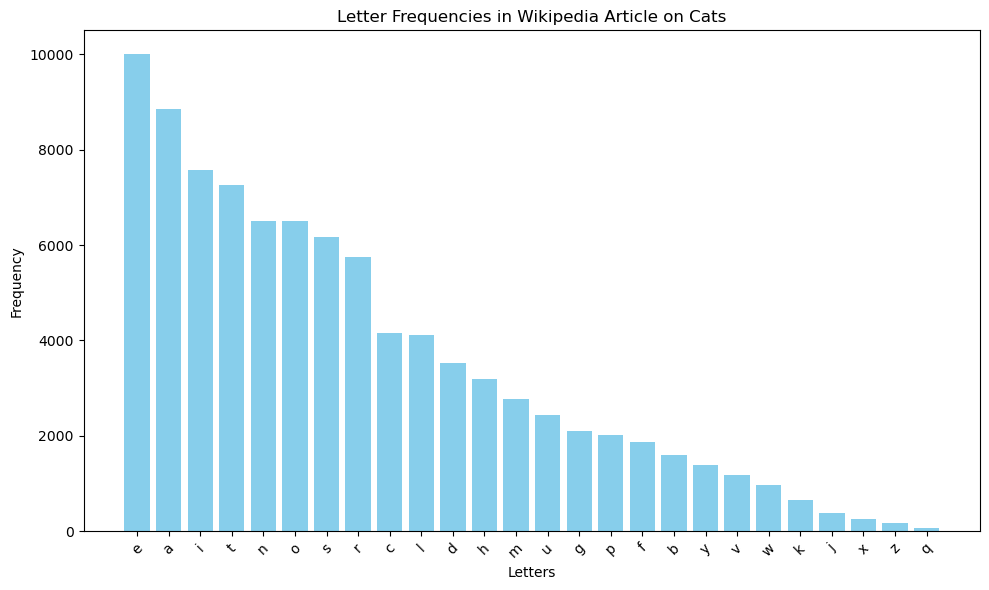

In [33]:
# Download wikipedia article on "Cat"
import requests
url = "https://en.wikipedia.org/wiki/Cat"
response = requests.get(url)
cat_text = response.text
# Extract text from HTML
from bs4 import BeautifulSoup
soup = BeautifulSoup(cat_text, 'html.parser')
cat_text = soup.get_text()
# Now let's count letter frequencies in the text
from collections import Counter
letter_counts = Counter(c.lower() for c in cat_text if c.isalpha())
# Sort by frequency
sorted_letter_counts = sorted(letter_counts.items(), key=lambda x: x[1], reverse=True)
# Plot the letter frequencies for the first 20 letters
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 6))
sorted_letter_counts = sorted_letter_counts[:26]  # Limit to top 20 letters 
letters, counts = zip(*sorted_letter_counts)
plt.bar(letters, counts, color='skyblue')
plt.xlabel('Letters')
plt.ylabel('Frequency')
plt.title('Letter Frequencies in Wikipedia Article on Cats')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

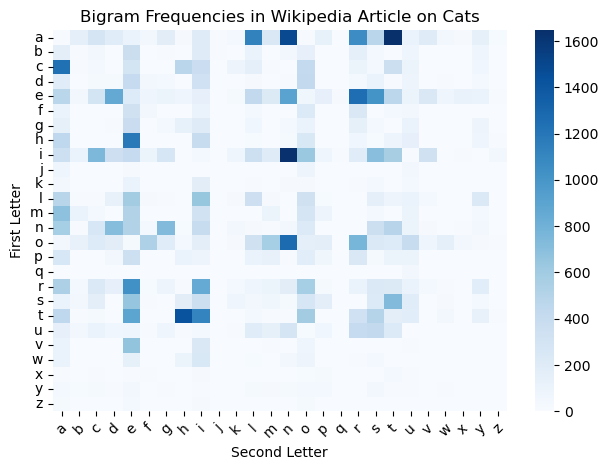

In [35]:
from collections import defaultdict
bigram_counts = defaultdict(int)
for i in range(len(cat_text) - 1):
    if cat_text[i].isalpha() and cat_text[i + 1].isalpha():
        a, b = cat_text[i].lower(), cat_text[i + 1].lower()
        # Only process standard English letters (a-z)
        if 'a' <= a <= 'z' and 'a' <= b <= 'z':
            bigram = (a, b)
            bigram_counts[bigram] += 1

# Sort by frequency
sorted_bigram_counts = sorted(bigram_counts.items(), key=lambda x: x[1], reverse=True)

# Plot the heatmap of bigram frequencies
import seaborn as sns
bigram_matrix = np.zeros((26, 26))
for (a, b), count in sorted_bigram_counts:
    bigram_matrix[ord(a) - ord('a'), ord(b) - ord('a')] = count

sns.heatmap(bigram_matrix, cmap='Blues')
plt.xlabel('Second Letter')
plt.ylabel('First Letter')
plt.title('Bigram Frequencies in Wikipedia Article on Cats')
plt.xticks(ticks=np.arange(26) + 0.5, labels=[chr(i + ord('a')) for i in range(26)], rotation=45)
plt.yticks(ticks=np.arange(26) + 0.5, labels=[chr(i + ord('a')) for i in range(26)], rotation=0)
plt.tight_layout()